# Thông tin


# Download data

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wenewone/cub2002011")

print("Path to dataset files:", path)

100%|██████████| 1.49G/1.49G [00:22<00:00, 72.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/wenewone/cub2002011/versions/7


In [ ]:
!mv /root/.cache/kagglehub/datasets/wenewone/cub2002011/versions/7 /content/cub2002011


# THƯ VIỆN

In [ ]:
import torch
import torchvision
import tensorflow as tf
from torchvision import datasets
from imutils import paths
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, DepthwiseConv2D, GlobalAveragePooling2D, Dense, ReLU, Flatten, Dropout

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, models, applications

import os
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random


# XỬ LÝ DỮ LIỆU

In [ ]:
# Đường dẫn đến tập dữ liệu Caltech101
base_dir = '/content/cub2002011/CUB_200_2011'
images_dir = os.path.join(base_dir, "images")
bb_dir = os.path.join(base_dir,'bounding_boxes.txt')
image_file = os.path.join(base_dir,'images.txt')
label_dir = os.path.join(base_dir,'image_class_labels.txt')

In [ ]:
bbox_df = pd.read_csv(bb_dir, sep=' ',
                      header=None,
                      names=['image_id', 'x', 'y', 'width', 'height'])

image_df = pd.read_csv(image_file, sep=' ',
                       header=None,
                       names=['image_id', 'image_path'])

# Hợp nhất các thông tin
data = pd.merge(image_df, bbox_df, on="image_id")

# Kiểm tra một số hàng dữ liệu
print(data.head())

   image_id                                         image_path      x      y  \
0         1  001.Black_footed_Albatross/Black_Footed_Albatr...   60.0   27.0   
1         2  001.Black_footed_Albatross/Black_Footed_Albatr...  139.0   30.0   
2         3  001.Black_footed_Albatross/Black_Footed_Albatr...   14.0  112.0   
3         4  001.Black_footed_Albatross/Black_Footed_Albatr...  112.0   90.0   
4         5  001.Black_footed_Albatross/Black_Footed_Albatr...   70.0   50.0   

   width  height  
0  325.0   304.0  
1  153.0   264.0  
2  388.0   186.0  
3  255.0   242.0  
4  134.0   303.0  


In [ ]:
class_names = pd.read_csv(os.path.join(base_dir, "classes.txt"),
                          delimiter=' ',
                          header=None,
                          names=['ID', 'Class Name'])

In [ ]:
class_names

,ID,Class Name
0,1,001.Black_footed_Albatross
1,2,002.Laysan_Albatross
2,3,003.Sooty_Albatross
3,4,004.Groove_billed_Ani
4,5,005.Crested_Auklet
...,...,...
195,196,196.House_Wren
196,197,197.Marsh_Wren
197,198,198.Rock_Wren
198,199,199.Winter_Wren


In [ ]:
labels = pd.read_csv(os.path.join(base_dir, "image_class_labels.txt"),
                     delimiter=' ',
                     header=None,
                     names=['ID', 'Class ID'])

In [ ]:
labels

,ID,Class ID
0,1,1
1,2,1
2,3,1
3,4,1
4,5,1
...,...,...
11783,11784,200
11784,11785,200
11785,11786,200
11786,11787,200


In [ ]:
train_test_split = pd.read_csv(os.path.join(base_dir, "train_test_split.txt"),
                               delimiter=' ',
                               header=None)[1]
train_test_split.value_counts()

,count
1,
1,5994
0,5794


In [ ]:
images_arr=[]
bounding_box=[]
for i,img_path in enumerate(image_df.image_path):
  img = cv2.imread(os.path.join(images_dir, img_path)) #Đọc ảnh
  size = img.shape #Lưu size
  new_bb = [bbox_df.x[i]/size[1],
            bbox_df.y[i]/size[0],
            bbox_df.width[i]/size[1],
            bbox_df.height[i]/size[0]] #chuẩn hóa BB
  img = cv2.resize(img, (224, 224)) #Resize
  img_arr= np.array(img) #Chuyển np
  images_arr.append(img_arr)
  bounding_box.append(new_bb)

In [ ]:
images_arr = np.array(images_arr)
print(images_arr.shape)

(11788, 224, 224, 3)


In [ ]:
print(bounding_box[0])

[0.12, 0.08059701492537313, 0.65, 0.9074626865671642]


In [ ]:
print(images_arr[0])

[[[  3   1   3]
  [  4   5   2]
  [  0   1   2]
  ...
  [  3   0   1]
  [ 11   2   4]
  [  1   2   1]]

 [[  3   3   1]
  [  6   1   5]
  [  1   2   2]
  ...
  [  2   0   1]
  [  6   5   1]
  [  7   4   6]]

 [[  5   5   3]
  [113  63  43]
  [142  81  26]
  ...
  [120  72  22]
  [ 89  58  36]
  [  5   2   1]]

 ...

 [[  7   4   4]
  [124 113 108]
  [175 152 130]
  ...
  [164 110  38]
  [115  92  53]
  [  8   3   7]]

 [[  8   1   2]
  [  3   2   3]
  [  1   0   5]
  ...
  [  1   2   1]
  [  0   5   4]
  [  7   0   1]]

 [[  3   1   4]
  [  4   6   1]
  [  3   0   1]
  ...
  [  3   1   0]
  [  7   0  13]
  [  7   1   3]]]


In [ ]:
def split(images_arr, labels, bounding_box, train_test_split):
    y_oh = pd.get_dummies(labels, columns=['Class ID'])
    y_oh = y_oh.astype(float)
    y_oh.drop("ID", axis=1, inplace=True)

    bounding_box = pd.DataFrame(bounding_box)
    X_train = images_arr[train_test_split == 1]
    X_test = images_arr[train_test_split == 0]
    y_train_class = y_oh[train_test_split == 1]
    y_test_class = y_oh[train_test_split == 0]
    y_train_bbox = bounding_box[train_test_split == 1]
    y_test_bbox = bounding_box[train_test_split == 0]

    return X_train, X_test, y_train_class, y_test_class, y_train_bbox, y_test_bbox

In [ ]:
X_train, X_test, y_train_class, y_test_class, y_train_bbox, y_test_bbox = split(images_arr, labels, bounding_box, train_test_split)

In [ ]:
print('X_train: ', X_train.shape)
print('X_test: ', X_test.shape)
print('y_train_class: ', y_train_class.shape)
print('y_test_class: ', y_test_class.shape)
print('y_train_bbox: ', y_train_bbox.shape)
print('y_test_bbox: ', y_test_bbox.shape)

X_train:  (5994, 224, 224, 3)
X_test:  (5794, 224, 224, 3)
y_train_class:  (5994, 200)
y_test_class:  (5794, 200)
y_train_bbox:  (5994, 4)
y_test_bbox:  (5794, 4)


In [ ]:
print(y_train_bbox.head())

         0         1         2         3
1  0.27800  0.089286  0.306000  0.785714
3  0.26988  0.180000  0.614458  0.484000
4  0.21148  0.131579  0.404834  0.797368
6  0.01400  0.220588  0.840000  0.770588
7  0.15600  0.219949  0.666000  0.404092


# Model

In [ ]:
# Base model
base_model = applications.ResNet50(include_top=False, input_shape=(224, 224, 3), weights='imagenet')
base_model.trainable = False  # Freeze pre-trained layers

# Add global average pooling
x = layers.GlobalAveragePooling2D()(base_model.output)

# Fully connected layers for bounding box prediction
bbox_head = layers.Dense(512, activation='relu')(x)
bbox_head = layers.Dense(256, activation='relu')(bbox_head)
bbox_head = layers.Dense(4, activation='sigmoid', name='bbox_output')(bbox_head)

# Fully connected layers for classification (optional)
class_head = layers.Dense(512, activation='relu')(x)
class_head = layers.Dense(256, activation='relu')(class_head)
class_head = layers.Dense(200, activation='softmax', name='class_output')(class_head)

# Define model with two outputs
model = models.Model(inputs=base_model.input, outputs=[bbox_head, class_head])

# Compile the model
model.compile(
    optimizer='adam',
    loss={
        'bbox_output': 'mean_absolute_error',  # Loss for bounding box regression
        'class_output': 'categorical_crossentropy'  # Loss for classification
    },
    metrics={
        'bbox_output': ['mae'],
        'class_output': ['accuracy']
    }
)

model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_pad (ZeroPadding2D) │ (None, 230, 230, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 112, 112, 64)   │          9,472 │ conv1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_bn                  │ (None, 112, 112, 64)   │            256 │ conv1_conv[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_relu (Activation)   │ (None, 112, 112, 64)   │              0 │ conv1_bn[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pad (ZeroPadding2D) │ (None, 114, 114, 64)   │              0 │ conv1_relu[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pool (MaxPooling2D) │ (None, 56, 56, 64)     │              0 │ pool1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 56, 56, 64)     │          4,160 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 56, 56, 64)     │         36,928 │ conv2_block1_1_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_2_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_2_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_conv       │ (None, 56, 56, 256)    │         16,640 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_3_conv       │ (None, 56, 56, 256)    │         16,640 │ conv2_block1_2_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├──────────────────────

 Total params: 26,000,972 (99.19 MB)

 Trainable params: 2,413,260 (9.21 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history = model.fit(
    X_train,
    {'bbox_output': y_train_bbox, 'class_output': y_train_class},
    epochs=20,
    batch_size=32
)


Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 33s 97ms/step - bbox_output_loss: 0.1964 - bbox_output_mae: 0.1964 - class_output_accuracy: 0.0602 - class_output_loss: 4.8291 - loss: 5.0256
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 78ms/step - bbox_output_loss: 0.0750 - bbox_output_mae: 0.0750 - class_output_accuracy: 0.3679 - class_output_loss: 2.4192 - loss: 2.4941
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - bbox_output_loss: 0.0689 - bbox_output_mae: 0.0689 - class_output_accuracy: 0.5699 - class_output_loss: 1.5410 - loss: 1.6099
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 81ms/step - bbox_output_loss: 0.0654 - bbox_output_mae: 0.0654 - class_output_accuracy: 0.6863 - class_output_loss: 1.0752 - loss: 1.1405
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step - bbox_output_loss: 0.0613 - bbox_output_mae: 0.0613 - class_output_accuracy: 0.7648 - class_output_loss: 0.7832 - loss: 0.8444
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 83ms/step - bbox_output_loss: 0.0594 - bbox_ou

In [ ]:
preds_bbox, preds_class = model.predict(X_test)

182/182 ━━━━━━━━━━━━━━━━━━━━ 22s 99ms/step


In [ ]:
print(preds_bbox.shape)
print(preds_class.shape)

(5794, 4)
(5794, 200)


In [ ]:
X_test[0].shape

(224, 224, 3)

In [ ]:
def calculate_iou(box1, box2):
    """
    Tính IoU giữa hai bounding box.
    box1 và box2 định dạng (x, y, width, height)
    """
    # Tính tọa độ góc trên bên trái và góc dưới bên phải của mỗi bounding box
    x1_min, y1_min = box1[0], box1[1]
    x1_max, y1_max = box1[0] + box1[2], box1[1] + box1[3]

    x2_min, y2_min = box2[0], box2[1]
    x2_max, y2_max = box2[0] + box2[2], box2[1] + box2[3]

    # Tính tọa độ giao nhau
    inter_x_min = max(x1_min, x2_min)
    inter_y_min = max(y1_min, y2_min)
    inter_x_max = min(x1_max, x2_max)
    inter_y_max = min(y1_max, y2_max)

    # Tính diện tích giao nhau
    inter_width = max(0, inter_x_max - inter_x_min)
    inter_height = max(0, inter_y_max - inter_y_min)
    inter_area = inter_width * inter_height

    # Tính diện tích của từng bounding box
    area_box1 = box1[2] * box1[3]
    area_box2 = box2[2] * box2[3]

    # Tính IoU
    union_area = area_box1 + area_box2 - inter_area
    iou = inter_area / union_area if union_area > 0 else 0

    return iou


In [ ]:
def show_image_with_bbox(img, bbox, label,ground_truth,color=(255, 0, 0)):
    """
    Hiển thị ảnh với bounding box và class.

    Args:
        img: Ảnh gốc (numpy array).
        bbox: Bounding box [x, y, width, height] (chuẩn hóa từ 0 đến 1).
        label: Index của class dự đoán.
        color: Màu sắc của bounding box (mặc định là màu đỏ).
        ground_truth: bounding box thực tế
    """

    # Kích thước ảnh
    h, w, _ = img.shape

    # Chuyển tọa độ bounding box từ [0, 1] về không gian gốc
    x = int(bbox[0] * w)
    y = int(bbox[1] * h)
    width = int(bbox[2] * w)
    height = int(bbox[3] * h)
    x, y, width, height = map(int, [x, y, width, height])
    print('Bounding box: ',x, y, width, height)

    img_bbox = img.copy()

    # Tạo bounding box trên ảnh

    # Ghi class name trên ảnh
    class_name= class_names.loc[class_names['ID'] == label, 'Class Name'].values[0]

    cv2.rectangle(img_bbox, (x, y), (x + width, y + height), color, 2)
    cv2.putText(img_bbox, class_name.split('.')[1], (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.3, color, 2)

    if isinstance(ground_truth, pd.Series):
        ground_truth = ground_truth.values

    #Vẽ ground_truth
    x_gt= int(ground_truth[0] * w)
    y_gt= int(ground_truth[1] * h)
    width_gt= int(ground_truth[2] * w)
    height_gt= int(ground_truth[3] * h)
    x_gt, y_gt, width_gt, height_gt = map(int, [x_gt, y_gt, width_gt, height_gt])
    print('Ground truth: ',x_gt, y_gt, width_gt, height_gt)
    # Vẽ bounding box ground truth
    cv2.rectangle(img_bbox, (x_gt, y_gt), (x_gt + width_gt, y_gt + height_gt), (0, 255, 0), 2)
    cv2.putText(img_bbox, 'Ground Truth', (x_gt, y_gt - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

    # Hiển thị ảnh
    print('Class name: ',class_name)
    plt.imshow(cv2.cvtColor(img_bbox, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()


In [ ]:
from sklearn.metrics import accuracy_score

preds_class_final = np.argmax(preds_class, axis=1)+1
y_test_classes = np.argmax(y_test_class, axis=1)+1
print(accuracy_score(preds_class_final, y_test_classes))

0.5081118398343114


True class: 78
Predict class: 78
IoU:  0.7734418535956058
Bounding box:  28 19 155 186
Ground truth:  16 37 175 159
Class name:  078.Gray_Kingbird


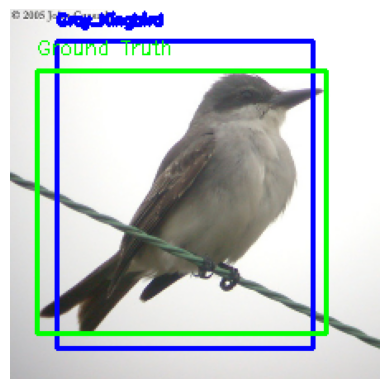

In [ ]:
i = random.randint(0, len(X_test))
print('True class:',y_test_classes[i])
print('Predict class:',preds_class_final[i])
print('IoU: ', calculate_iou(preds_bbox[i], y_test_bbox.iloc[i].values))
show_image_with_bbox(X_test[i], preds_bbox[i], preds_class_final[i],y_test_bbox.iloc[i])
